# Лабораторна робота №2
## Розвідувальний аналіз енергоспоживання будинку

**Ковальчук Ярослав · АтаВДвR-11**  
Курс: Аналіз та візуалізація даних у R

Мета — дослідити розподіл енергоспоживання та його зв’язки з часом доби, календарем, температурою, вологістю й освітленням. Регресійні моделі в цій роботі не навчаються.

## 1. Дані та дослідницькі запитання

Використано **Appliances Energy Prediction**, автор Luis Candanedo, 2017. Джерело: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction), DOI: [10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G). Ліцензія — **CC BY 4.0**. Файл отримано з [репозиторію автора](https://github.com/LuisM78/Appliances-energy-prediction-data).

Одиниця спостереження — десятихвилинний інтервал вимірювань одного енергоефективного будинку в Бельгії. Ціль `Appliances` — енергія, спожита побутовими приладами, у Wh за інтервал. Це кількісна величина з округленими вимірюваннями, придатна для майбутньої задачі регресії. Це не потужність у W і не загальне споживання всіх будинків.

Потенційні фактори: температура й вологість кімнат, зовнішні погодні показники, освітлення та календарні характеристики. Ціль не обчислюється безпосередньо з цих стовпців. Дані містять достатньо спостережень для розподілів, групових порівнянь і багатовимірних зв’язків.

1. Який розподіл споживання та наскільки виражені піки?
2. Як споживання змінюється протягом доби?
3. Чим відрізняються будні та вихідні?
4. Як споживання пов’язане з температурою, вологістю й освітленням?
5. Чи зберігаються зв’язки при порівнянні однакових годин і типів дня?

## 2. Підготовка середовища
### 2.1. Встановлення пакетів
Пакети встановлюються лише за відсутності. Для першого запуску потрібен інтернет; подальший аналіз використовує локальні дані.

In [1]:
if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_ALL", "English_United States.utf8"))
packages <- c("readr", "dplyr", "tidyr", "ggplot2", "lubridate", "svglite", "IRkernel")
missing_packages <- setdiff(packages, rownames(installed.packages()))
if (length(missing_packages)) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}

### 2.2. Бібліотеки та шляхи
Ноутбук можна запускати з папки `lab02` або `lab02/notebooks`. Вихідний CSV залишається незмінним.

In [2]:
suppressWarnings(suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(lubridate)
}))
root <- if (file.exists("data/raw/energydata_complete.csv")) "." else ".."
stopifnot(file.exists(file.path(root, "data/raw/energydata_complete.csv")))
path <- function(...) file.path(root, ...)
for (folder in c("data/processed", "outputs/tables", "outputs/figures", "outputs/metadata")) {
  dir.create(path(folder), recursive = TRUE, showWarnings = FALSE)
}
options(repr.plot.width = 11, repr.plot.height = 5.5, repr.plot.res = 120)
blue <- "#1B4F8A"; orange <- "#C46B36"; paper <- "#FFFFFF"
if (!"Unbounded" %in% systemfonts::system_fonts()$family) {
  systemfonts::register_font("Unbounded", plain = path("reports/Unbounded-Regular.ttf"),
                            bold = path("reports/Unbounded-Bold.ttf"))
}
font_css <- paste0("@font-face{font-family:Unbounded;font-weight:400;src:url(data:font/ttf;base64,",
  base64enc::base64encode(path("reports/Unbounded-Regular.ttf")), ")}@font-face{font-family:Unbounded;font-weight:700;src:url(data:font/ttf;base64,",
  base64enc::base64encode(path("reports/Unbounded-Bold.ttf")), ")}")
theme_set(theme_minimal(base_size = 16, base_family = "Unbounded") + theme(
  plot.background = element_rect(fill = paper, colour = NA),
  panel.background = element_rect(fill = paper, colour = NA),
  panel.grid.minor = element_blank(),
  panel.grid.major.x = element_blank(),
  panel.grid.major.y = element_line(colour = "#EBEBEB"),
  plot.title = element_text(face = "bold", colour = "#1F2328"),
  axis.title = element_text(colour = "#3E4247", size = 16),
  axis.text = element_text(size = 16),
  strip.text = element_text(size = 14),
  legend.position = "top"))
save_table <- function(x, name) write_csv(x, path("outputs/tables", paste0(name, ".csv")))
save_plot <- function(p, name, width = 11, height = 5.5) {
  p <- p + labs(title = NULL)
  ggsave(path("outputs/figures", paste0(name, ".svg")), p,
         device = svglite::svglite, width = width, height = height, bg = paper)
  svg_file <- path("outputs/figures", paste0(name, ".svg"))
  svg_text <- paste(readLines(svg_file, encoding = "UTF-8", warn = FALSE), collapse = "\n")
  svg_text <- sub("<defs>", paste0("<defs><style>", font_css, "</style>"), svg_text, fixed = TRUE)
  writeLines(svg_text, svg_file, useBytes = TRUE)
  IRdisplay::display_svg(file = path("outputs/figures", paste0(name, ".svg")))
}
note <- function(text) IRdisplay::display_markdown(text)
fmt <- function(x, digits = 1) chartr("-", "−", formatC(x, digits = digits, format = "f", decimal.mark = ","))

## 3. Первинне ознайомлення
### 3.1. Завантаження та структура
Зберігаємо всі початкові стовпці. `rv1` і `rv2` — випадкові змінні, додані автором для експериментів; вони не мають предметного змісту й не входять до аналізу факторів.

In [3]:
raw <- read_csv(path("data/raw/energydata_complete.csv"),
  col_types = cols(date = col_character(), .default = col_double()),
  na = c("", "NA", "NaN", "?"), show_col_types = FALSE)
stopifnot(nrow(problems(raw)) == 0)
cat("Рядків:", nrow(raw), "| Стовпців:", ncol(raw), "\n")
print(head(raw[, 1:8]))
print(tibble(variable = names(raw), type = vapply(raw, function(x) class(x)[1], character(1))), n = 29)

Рядків: 19735 | Стовпців: 29 
# A tibble: 6 × 8
  date                Appliances lights    T1  RH_1    T2  RH_2    T3
  <chr>                    <dbl>  <dbl> <dbl> <dbl> <dbl> <dbl> <dbl>
1 2016-01-11 17:00:00         60     30  19.9  47.6  19.2  44.8  19.8
2 2016-01-11 17:10:00         60     30  19.9  46.7  19.2  44.7  19.8
3 2016-01-11 17:20:00         50     30  19.9  46.3  19.2  44.6  19.8
4 2016-01-11 17:30:00         50     40  19.9  46.1  19.2  44.6  19.8
5 2016-01-11 17:40:00         60     40  19.9  46.3  19.2  44.5  19.8
6 2016-01-11 17:50:00         50     40  19.9  46.0  19.2  44.5  19.8
# A tibble: 29 × 2
   variable    type     
   <chr>       <chr>    
 1 date        character
 2 Appliances  numeric  
 3 lights      numeric  
 4 T1          numeric  
 5 RH_1        numeric  
 6 T2          numeric  
 7 RH_2        numeric  
 8 T3          numeric  
 9 RH_3        numeric  
10 T4          numeric  
11 RH_4        numeric  
12 T5          numeric  
13 RH_5        numeric 

In [4]:
dictionary <- tibble(
  variable = names(raw),
  meaning = c("Час вимірювання", "Енергія побутових приладів", "Енергія освітлення",
    "Температура кухні", "Вологість кухні", "Температура вітальні", "Вологість вітальні",
    "Температура пральні", "Вологість пральні", "Температура кабінету", "Вологість кабінету",
    "Температура ванної", "Вологість ванної", "Температура з північного боку будинку", "Вологість з північного боку будинку",
    "Температура кімнати для прасування", "Вологість кімнати для прасування",
    "Температура кімнати підлітка", "Вологість кімнати підлітка",
    "Температура спальні батьків", "Вологість спальні батьків",
    "Зовнішня температура метеостанції", "Атмосферний тиск", "Зовнішня вологість",
    "Швидкість вітру", "Видимість", "Температура точки роси", "Випадкова змінна автора", "Випадкова змінна автора"),
  unit = c("YYYY-MM-DD hh:mm:ss", "Wh", "Wh", rep(c("°C", "%"), 9),
           "°C", "mm Hg", "%", "m/s", "km", "°C", "—", "—"))
save_table(dictionary, "variable_dictionary")
print(dictionary, n = 29)

# A tibble: 29 × 3
   variable    meaning                               unit               
   <chr>       <chr>                                 <chr>              
 1 date        Час вимірювання                       YYYY-MM-DD hh:mm:ss
 2 Appliances  Енергія побутових приладів            Wh                 
 3 lights      Енергія освітлення                    Wh                 
 4 T1          Температура кухні                     °C                 
 5 RH_1        Вологість кухні                       %                  
 6 T2          Температура вітальні                  °C                 
 7 RH_2        Вологість вітальні                    %                  
 8 T3          Температура пральні                   °C                 
 9 RH_3        Вологість пральні                     %                  
10 T4          Температура кабінету                  °C                 
11 RH_4        Вологість кабінету                    %                  
12 T5          Температура ванно

### 3.2. Часові та категоріальні ознаки
Джерело не вказує часового поясу. Позначення UTC нижче використовується лише як технічна шкала для розбору надрукованого часу: конвертація місцевого часу не виконується. Через цю невизначеність не робимо висновків про перехід на літній час.

`day_type` та `weekday` — фактори, отримані з календаря. `hour` — циклічна часова ознака, а не звичайна лінійна шкала.

In [5]:
parsed_time <- ymd_hms(raw$date, tz = "UTC", quiet = TRUE)
stopifnot(!anyNA(parsed_time))
data <- raw |> mutate(
  timestamp = parsed_time, calendar_date = as.Date(timestamp, tz = "UTC"),
  hour = hour(timestamp), weekday_number = wday(timestamp, week_start = 1),
  weekday = factor(weekday_number, levels = 1:7,
    labels = c("Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд")),
  day_type = factor(if_else(weekday_number >= 6, "Вихідні", "Будні"),
                    levels = c("Будні", "Вихідні"))) |> arrange(timestamp)
print(data |> select(date, hour, weekday, day_type) |> head())
cat("Період:", min(raw$date), "—", max(raw$date), "\n")

# A tibble: 6 × 4
  date                 hour weekday day_type
  <chr>               <int> <fct>   <fct>   
1 2016-01-11 17:00:00    17 Пн      Будні   
2 2016-01-11 17:10:00    17 Пн      Будні   
3 2016-01-11 17:20:00    17 Пн      Будні   
4 2016-01-11 17:30:00    17 Пн      Будні   
5 2016-01-11 17:40:00    17 Пн      Будні   
6 2016-01-11 17:50:00    17 Пн      Будні   
Період: 2016-01-11 17:00:00 — 2016-05-27 18:00:00 


## 4. Якість даних
Перевіряємо пропуски в кожному стовпці, повні дублікати та дублікати часу. Від’ємне споживання, вологість поза 0–100%, від’ємні швидкість вітру чи видимість є підставою перевірити запис. Низька або висока температура сама по собі помилкою не вважається.

In [6]:
missingness <- tibble(variable = names(raw), missing = colSums(is.na(raw)),
                      percent = colMeans(is.na(raw)) * 100)
humidity <- grep("^RH", names(raw), value = TRUE)
quality <- tibble(check = c("Рядки", "Стовпці", "Пропущені комірки", "Повні дублікати",
  "Повторні часові мітки", "Кроки часу не 600 секунд", "Від’ємне споживання",
  "Вологість поза 0–100%", "Від’ємний вітер або видимість"),
  value = c(nrow(raw), ncol(raw), sum(is.na(raw)), sum(duplicated(raw)),
    sum(duplicated(data$timestamp)), sum(as.numeric(diff(data$timestamp), units = "secs") != 600),
    sum(raw$Appliances < 0 | raw$lights < 0, na.rm = TRUE),
    sum(vapply(raw[humidity], function(x) sum(x < 0 | x > 100, na.rm = TRUE), numeric(1))),
    sum(raw$Windspeed < 0 | raw$Visibility < 0, na.rm = TRUE)))
save_table(missingness, "missingness"); save_table(quality, "quality")
print(quality)
print(missingness, n = 29)
stopifnot(all(quality$value[3:9] == 0))
note("**Рішення.** Пропусків, дублікатів, нерегулярних кроків і перевірених фізичних порушень не виявлено. Імпутація та видалення рядків не потрібні. Це не виключає похибок датчиків або невідомих змін поведінки мешканців.")

# A tibble: 9 × 2
  check                         value
  <chr>                         <dbl>
1 Рядки                         19735
2 Стовпці                          29
3 Пропущені комірки                 0
4 Повні дублікати                   0
5 Повторні часові мітки             0
6 Кроки часу не 600 секунд          0
7 Від’ємне споживання               0
8 Вологість поза 0–100%             0
9 Від’ємний вітер або видимість     0
# A tibble: 29 × 3
   variable    missing percent
   <chr>         <dbl>   <dbl>
 1 date              0       0
 2 Appliances        0       0
 3 lights            0       0
 4 T1                0       0
 5 RH_1              0       0
 6 T2                0       0
 7 RH_2              0       0
 8 T3                0       0
 9 RH_3              0       0
10 T4                0       0
11 RH_4              0       0
12 T5                0       0
13 RH_5              0       0
14 T6                0       0
15 RH_6              0       0
16 T7             

**Рішення.** Пропусків, дублікатів, нерегулярних кроків і перевірених фізичних порушень не виявлено. Імпутація та видалення рядків не потрібні. Це не виключає похибок датчиків або невідомих змін поведінки мешканців.

## 5. Описова статистика та одновимірний аналіз
Середнє характеризує загальний рівень, медіана — типовий інтервал за асиметричного розподілу, квартилі — центральні 50% значень. Стандартне відхилення чутливе до піків. У таблиці наведено всі змістовні числові показники, окрім календарних кодів.

In [7]:
numeric_vars <- setdiff(names(raw), c("date", "rv1", "rv2"))
statistics <- bind_rows(lapply(numeric_vars, function(v) {
  x <- data[[v]]
  tibble(variable = v, n = sum(!is.na(x)), mean = mean(x), median = median(x),
    sd = sd(x), min = min(x), q25 = unname(quantile(x, .25)),
    q75 = unname(quantile(x, .75)), p95 = unname(quantile(x, .95)), max = max(x),
    IQR = IQR(x), range = max(x) - min(x))
}))
categories <- data |> count(day_type, name = "n") |> mutate(percent = 100 * n / sum(n))
save_table(statistics, "descriptive_statistics"); save_table(categories, "day_type_counts")
print(statistics, n = 26, width = Inf)
print(categories)
target <- statistics |> filter(variable == "Appliances")
note(paste0("Середнє споживання — **", fmt(target$mean), " Wh**, медіана — **", fmt(target$median, 0),
  " Wh**. Центральні 50% інтервалів лежать між ", fmt(target$q25, 0), " та ", fmt(target$q75, 0),
  " Wh; максимум — ", fmt(target$max, 0), " Wh. Середнє вище медіани: правий хвіст помітно підвищує його."))

# A tibble: 26 × 12
   variable        n   mean median     sd    min    q25    q75   p95    max
   <chr>       <int>  <dbl>  <dbl>  <dbl>  <dbl>  <dbl>  <dbl> <dbl>  <dbl>
 1 Appliances  19735  97.7   60    103.    10     50    100    330   1080  
 2 lights      19735   3.80   0      7.94   0      0      0     20     70  
 3 T1          19735  21.7   21.6    1.61  16.8   20.8   22.6   24.7   26.3
 4 RH_1        19735  40.3   39.7    3.98  27.0   37.3   43.1   47.3   63.4
 5 T2          19735  20.3   20      2.19  16.1   18.8   21.5   24.6   29.9
 6 RH_2        19735  40.4   40.5    4.07  20.5   37.9   43.3   46.7   56.0
 7 T3          19735  22.3   22.1    2.01  17.2   20.8   23.3   26.2   29.2
 8 RH_3        19735  39.2   38.5    3.25  28.8   36.9   41.8   45.1   50.2
 9 T4          19735  20.9   20.7    2.04  15.1   19.5   22.1   24.5   26.2
10 RH_4        19735  39.0   38.4    4.34  27.7   35.5   42.2   46.8   51.1
11 T5          19735  19.6   19.4    1.84  15.3   18.3   20.6   23.4

Середнє споживання — **97,7 Wh**, медіана — **60 Wh**. Центральні 50% інтервалів лежать між 50 та 100 Wh; максимум — 1080 Wh. Середнє вище медіани: правий хвіст помітно підвищує його.

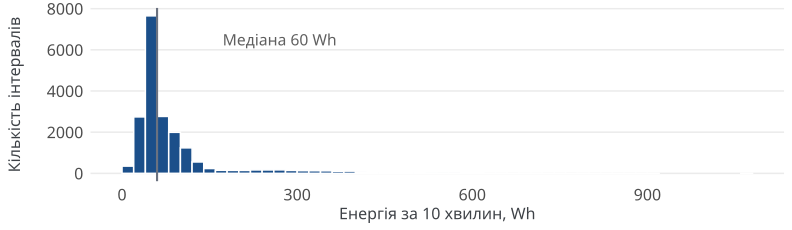

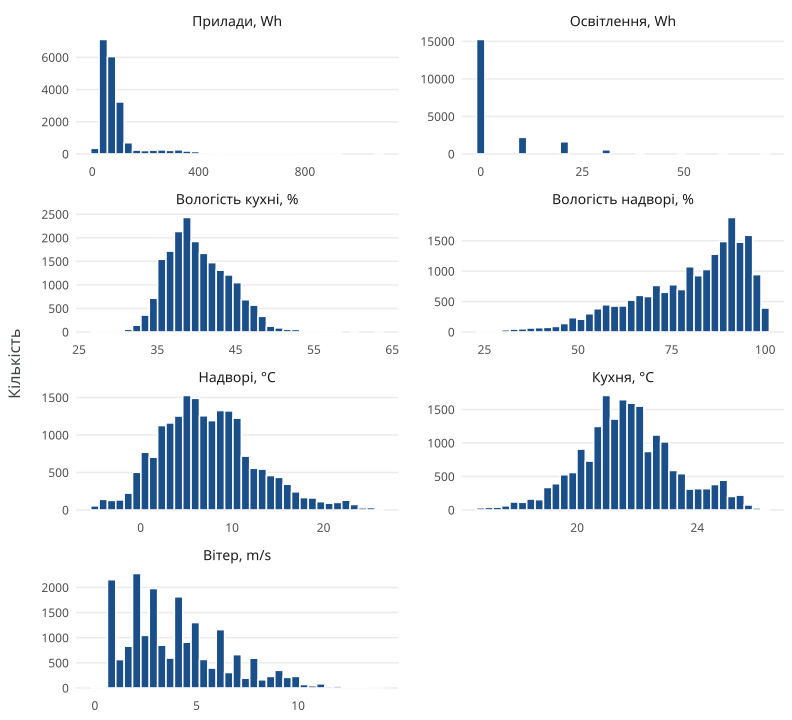

In [8]:
p_distribution <- ggplot(data, aes(Appliances)) +
  geom_histogram(binwidth = 20, boundary = 0, fill = blue, colour = paper) +
  geom_vline(xintercept = target$median, colour = "#6B7280", linewidth = 1) +
  annotate("text", x = 270, y = 6500, label = paste("Медіана", fmt(target$median, 0), "Wh"),
           colour = "#5F5F5F", size = 5.5) +
  labs(title = "Більшість інтервалів мають невелике споживання",
       x = "Енергія за 10 хвилин, Wh", y = "Кількість інтервалів")
save_plot(p_distribution, "target_distribution", height = 3.2)
important <- c("Appliances", "lights", "T1", "RH_1", "T_out", "RH_out", "Windspeed")
labels <- c(Appliances = "Прилади, Wh", lights = "Освітлення, Wh", T1 = "Кухня, °C",
            RH_1 = "Вологість кухні, %", T_out = "Надворі, °C", RH_out = "Вологість надворі, %", Windspeed = "Вітер, m/s")
long <- data |> select(all_of(important)) |> pivot_longer(everything(), names_to = "variable")
p_factors <- ggplot(long, aes(value)) + geom_histogram(bins = 35, fill = blue, colour = paper) +
  facet_wrap(~variable, scales = "free", ncol = 2, labeller = as_labeller(labels)) +
  scale_x_continuous(n.breaks = 4) + theme(axis.text = element_text(size = 12)) +
  labs(title = "Розподіли семи основних показників", x = NULL, y = "Кількість")
save_plot(p_factors, "factor_distributions", height = 10)

Освітлення має багато нульових або малих значень, тому його не варто трактувати як нормально розподілену ознаку. Температури, вологість і вітер мають інші масштаби та форми розподілу. Нормалізація не є метою EDA: вихідні одиниці збережено. Для читання щільних ділянок на окремих графіках використано логарифмічну вісь, без заміни початкових значень.

### 5.1. Потенційні викиди
IQR — міжквартильний розмах, Q3 − Q1. Правило 1,5 IQR — спосіб позначити незвичні значення, а не доказ помилки. Перевіряємо, як механічне вилучення піків змінило б описову статистику.

# A tibble: 2 × 5
  scenario                                 n  mean median    sd
  <chr>                                <int> <dbl>  <dbl> <dbl>
1 Усі вимірювання                      19735  97.7     60 103. 
2 Без позначених IQR (лише порівняння) 17597  67.2     60  28.5


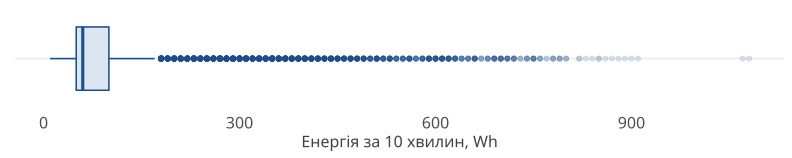

Верхня межа IQR — **175 Wh**. Позначено **2138 інтервалів (10,8% вибірки)**. Вилучення знизило б середнє з 97,7 до 67,2 Wh. Джерело не позначає ці піки як помилки; фізичних суперечностей не виявлено. Залишаємо всі записи й додаємо прапорець для прозорості.

In [9]:
q <- quantile(data$Appliances, c(.25, .75))
lower <- q[1] - 1.5 * diff(q); upper <- q[2] + 1.5 * diff(q)
data <- data |> mutate(iqr_flag = Appliances < lower | Appliances > upper)
outlier_comparison <- bind_rows(
  data |> summarise(scenario = "Усі вимірювання", n = n(), mean = mean(Appliances), median = median(Appliances), sd = sd(Appliances)),
  data |> filter(!iqr_flag) |> summarise(scenario = "Без позначених IQR (лише порівняння)", n = n(), mean = mean(Appliances), median = median(Appliances), sd = sd(Appliances)))
save_table(outlier_comparison, "outlier_sensitivity")
print(outlier_comparison)
p_outliers <- ggplot(data, aes(x = "", y = Appliances)) +
  geom_boxplot(fill = "#DCE6F2", colour = blue, outlier.alpha = .15) +
  coord_flip() + labs(title = "Високі піки залишаються в аналізі", x = NULL, y = "Енергія за 10 хвилин, Wh")
save_plot(p_outliers, "outliers", height = 2.2)
note(paste0("Верхня межа IQR — **", fmt(upper, 0), " Wh**. Позначено **", sum(data$iqr_flag),
  " інтервалів (", fmt(mean(data$iqr_flag) * 100), "% вибірки)**. Вилучення знизило б середнє з ",
  fmt(outlier_comparison$mean[1]), " до ", fmt(outlier_comparison$mean[2]),
  " Wh. Джерело не позначає ці піки як помилки; фізичних суперечностей не виявлено. Залишаємо всі записи й додаємо прапорець для прозорості."))

## 6. Часова структура та групові порівняння
### 6.1. Добове споживання
Енергію у Wh сумуємо та ділимо на 1000 для отримання kWh. Перший і останній день неповні, тому для добових сум використовуємо тільки дні зі 144 інтервалами.

# A tibble: 1 × 3
   days complete_days partial_days
  <int>         <int>        <int>
1   138           136            2


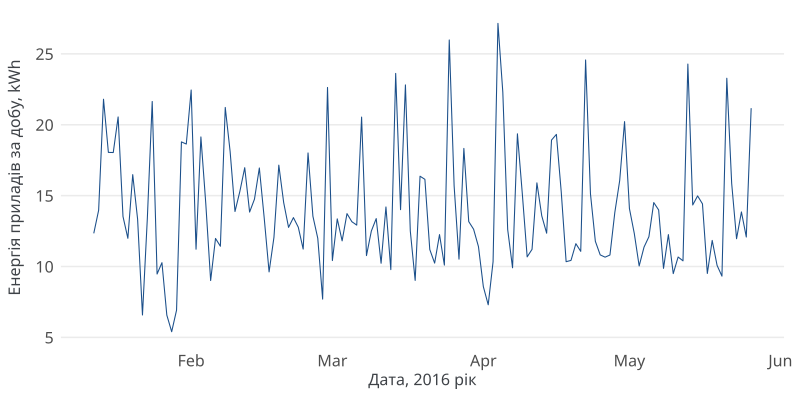

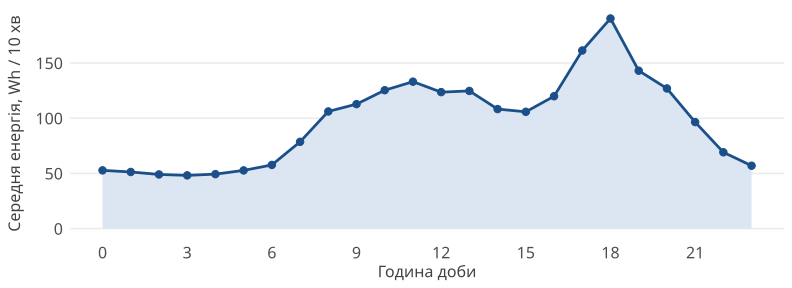

Пік погодинного середнього — о **18:00** (190,4 Wh за інтервал), мінімум — о 3:00 (48,2 Wh). Різниця приблизно у 3,9 раза. Це усереднені профілі, а не розклад кожного окремого дня.

In [10]:
daily <- data |> group_by(calendar_date, day_type) |> summarise(n = n(),
  energy_kwh = sum(Appliances) / 1000, .groups = "drop") |> mutate(complete = n == 144)
save_table(daily, "daily_energy")
print(daily |> summarise(days = n(), complete_days = sum(complete), partial_days = sum(!complete)))
p_daily <- ggplot(filter(daily, complete), aes(calendar_date, energy_kwh)) +
  geom_line(colour = blue, linewidth = .5) +
  labs(title = "Добові суми помітно відрізняються", x = "Дата, 2016 рік", y = "Енергія приладів за добу, kWh")
save_plot(p_daily, "daily_energy")
hourly <- data |> group_by(hour, day_type) |> summarise(n = n(), mean = mean(Appliances),
  median = median(Appliances), q25 = quantile(Appliances, .25), q75 = quantile(Appliances, .75), .groups = "drop")
hourly_all <- data |> group_by(hour) |> summarise(mean = mean(Appliances), median = median(Appliances), .groups = "drop")
save_table(hourly, "hourly_profiles"); save_table(hourly_all, "hourly_overall")
p_hour <- ggplot(hourly_all, aes(hour, mean)) + geom_area(fill = "#DCE6F2") +
  geom_line(colour = blue, linewidth = 1.3) + geom_point(colour = blue, size = 3) +
  scale_x_continuous(breaks = seq(0, 23, 3)) +
       labs(title = "Середнє споживання найвище ввечері", x = "Година доби", y = "Середня енергія, Wh / 10 хв")
save_plot(p_hour, "hourly_profile", height = 4)
peak <- hourly_all |> slice_max(mean, n = 1, with_ties = FALSE)
low <- hourly_all |> slice_min(mean, n = 1, with_ties = FALSE)
note(paste0("Пік погодинного середнього — о **", peak$hour, ":00** (", fmt(peak$mean),
  " Wh за інтервал), мінімум — о ", low$hour, ":00 (", fmt(low$mean),
  " Wh). Різниця приблизно у ", fmt(peak$mean / low$mean), " раза. Це усереднені профілі, а не розклад кожного окремого дня."))

### 6.2. Будні та вихідні
Порівнюємо як загальні середні, так і профілі за однаковою годиною. Кількість спостережень у групах неоднакова, тому порівнюємо рівні, а не загальні суми.

# A tibble: 2 × 5
  day_type     n  mean median    sd
  <fct>    <int> <dbl>  <dbl> <dbl>
1 Будні    14263  96.6     60  103.
2 Вихідні   5472 101.      70  101.


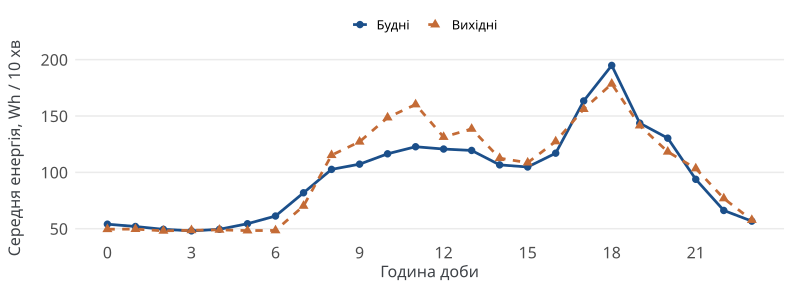

У будні середнє — **96,6 Wh**, у вихідні — **100,6 Wh**: різниця 4,0 Wh (4,1%). Невелика загальна різниця приховує відмінності за годинами. Це опис конкретного періоду, а не доказ впливу вихідного дня.

In [11]:
groups <- data |> group_by(day_type) |> summarise(n = n(), mean = mean(Appliances),
  median = median(Appliances), sd = sd(Appliances), .groups = "drop")
save_table(groups, "day_type_summary"); print(groups)
p_groups <- ggplot(hourly, aes(hour, mean, colour = day_type, linetype = day_type, shape = day_type)) +
  geom_line(linewidth = 1.3) + geom_point(size = 3) +
  scale_colour_manual(values = c("Будні" = blue, "Вихідні" = orange)) +
  scale_x_continuous(breaks = seq(0, 23, 3)) +
  labs(title = "Будні й вихідні мають різні добові профілі", x = "Година доби", y = "Середня енергія, Wh / 10 хв", colour = NULL, linetype = NULL, shape = NULL)
save_plot(p_groups, "weekday_weekend", height = 4)
week_mean <- groups$mean[groups$day_type == "Будні"]
end_mean <- groups$mean[groups$day_type == "Вихідні"]
note(paste0("У будні середнє — **", fmt(week_mean), " Wh**, у вихідні — **", fmt(end_mean),
  " Wh**: різниця ", fmt(end_mean - week_mean), " Wh (", fmt((end_mean / week_mean - 1) * 100),
  "%). Невелика загальна різниця приховує відмінності за годинами. Це опис конкретного періоду, а не доказ впливу вихідного дня."))

## 7. Двовимірний аналіз
Розглядаємо зв’язки цілі з освітленням, температурою та вологістю. Через велику кількість збігів групуємо всі спостереження у двовимірні комірки: колір показує кількість інтервалів у комірці за логарифмічною шкалою. Логарифмічна вісь для енергії допомагає бачити центральну частину; нульове освітлення не логарифмується.

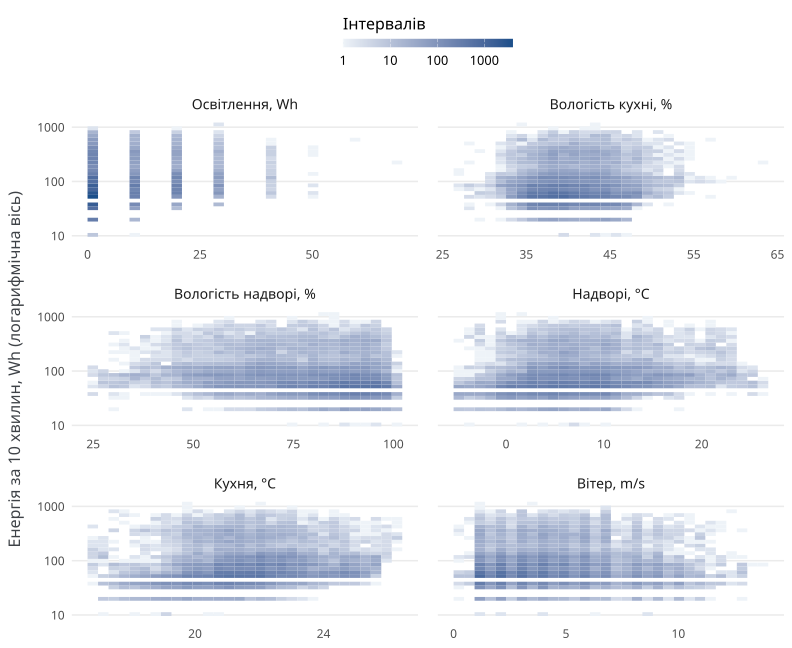

# A tibble: 25 × 3
   variable      pearson spearman
   <chr>           <dbl>    <dbl>
 1 T2           0.120     0.305  
 2 lights       0.197     0.302  
 3 RH_out      -0.152    -0.269  
 4 T1           0.0554    0.244  
 5 T6           0.118     0.242  
 6 T8           0.0396    0.236  
 7 RH_6        -0.0832   -0.230  
 8 RH_8        -0.0940   -0.217  
 9 T3           0.0851    0.217  
10 T_out        0.0992    0.216  
11 T4           0.0403    0.207  
12 T5           0.0198    0.186  
13 T7           0.0258    0.182  
14 T9           0.0100    0.167  
15 RH_9        -0.0515   -0.165  
16 RH_2        -0.0605   -0.120  
17 RH_7        -0.0556   -0.119  
18 Windspeed    0.0871    0.112  
19 Press_mm_hg -0.0349   -0.0962 
20 Tdewpoint    0.0154    0.0752 
21 RH_1         0.0860    0.0605 
22 RH_3         0.0363   -0.0571 
23 RH_5         0.00695  -0.0449 
24 RH_4         0.0170   -0.0202 
25 Visibility   0.000230 -0.00355


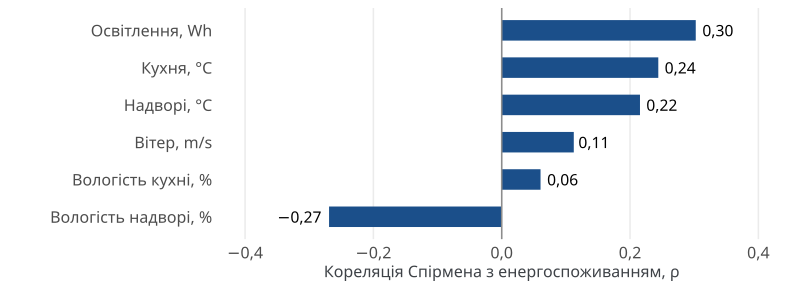

Кореляція Пірсона описує лінійний зв’язок і чутлива до піків; Спірмена — монотонний зв’язок рангів. Відмінність коефіцієнтів може бути пов’язана з асиметрією, нелінійністю та викидами; вона не є окремим доказом конкретної причини.

In [12]:
relations <- data |> select(Appliances, lights, T1, RH_1, T_out, RH_out, Windspeed) |>
  pivot_longer(-Appliances, names_to = "factor", values_to = "value")
p_relations <- ggplot(relations, aes(value, Appliances)) +
  geom_bin_2d(bins = 30) + scale_y_log10() +
  scale_fill_gradient(low = "#EEF3F8", high = blue, trans = "log10", name = "Інтервалів") +
  guides(fill = guide_colourbar(barwidth = grid::unit(6, "cm"),
    barheight = grid::unit(.3, "cm"), title.position = "top")) +
  scale_x_continuous(n.breaks = 4) +
  facet_wrap(~factor, scales = "free_x", ncol = 2, labeller = as_labeller(labels)) +
  theme(axis.text = element_text(size = 12), panel.spacing = grid::unit(.7, "cm")) +
  labs(title = "Окремі фактори не пояснюють усієї мінливості", x = NULL,
       y = "Енергія за 10 хвилин, Wh (логарифмічна вісь)")
save_plot(p_relations, "factor_relationships", height = 9)
target_cor <- bind_rows(lapply(setdiff(numeric_vars, "Appliances"), function(v)
  tibble(variable = v, pearson = cor(data[[v]], data$Appliances),
         spearman = cor(data[[v]], data$Appliances, method = "spearman")))) |>
  arrange(desc(abs(spearman)))
save_table(target_cor, "target_correlations"); print(target_cor, n = 25)
selected_cor <- target_cor |> filter(variable %in% setdiff(important, "Appliances")) |>
  mutate(label = unname(labels[variable]))
p_target_cor <- ggplot(selected_cor, aes(spearman, reorder(label, spearman))) +
  geom_col(fill = blue, width = .55) +
  geom_text(aes(label = fmt(spearman, 2), hjust = if_else(spearman >= 0, -.15, 1.15)), size = 5.5) +
  geom_vline(xintercept = 0, colour = "#8C8C8C") +
  scale_x_continuous(limits = c(-.4, .4), labels = function(x) fmt(x, 1)) +
  theme(panel.grid.major.y = element_blank(), panel.grid.major.x = element_line(colour = "#EBEBEB")) +
  labs(x = "Кореляція Спірмена з енергоспоживанням, ρ", y = NULL)
save_plot(p_target_cor, "target_correlations", height = 4)
note("Кореляція Пірсона описує лінійний зв’язок і чутлива до піків; Спірмена — монотонний зв’язок рангів. Відмінність коефіцієнтів може бути пов’язана з асиметрією, нелінійністю та викидами; вона не є окремим доказом конкретної причини.")

## 8. Багатовимірний аналіз
### 8.1. Кореляційна структура
Окрім зв’язку з ціллю, перевіряємо зв’язки між самими факторами. Температури кімнат можуть змінюватись разом; тому їх не слід вважати незалежними джерелами інформації.

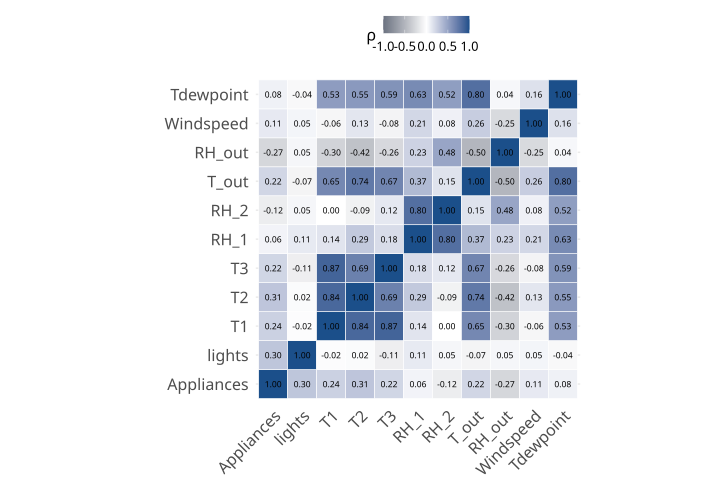

           Appliances lights    T1   T2    T3
Appliances       1.00   0.30  0.24 0.31  0.22
lights           0.30   1.00 -0.02 0.02 -0.11
T1               0.24  -0.02  1.00 0.84  0.87
T2               0.31   0.02  0.84 1.00  0.69
T3               0.22  -0.11  0.87 0.69  1.00


In [13]:
corr_vars <- c("Appliances", "lights", "T1", "T2", "T3", "RH_1", "RH_2", "T_out", "RH_out", "Windspeed", "Tdewpoint")
cor_matrix <- cor(as.data.frame(data[corr_vars]), method = "spearman")
cor_long <- as.data.frame(as.table(cor_matrix)) |> as_tibble() |> rename(x = Var1, y = Var2, rho = Freq)
save_table(cor_long, "spearman_matrix")
p_corr <- ggplot(cor_long, aes(x, y, fill = rho)) + geom_tile(colour = paper) +
  geom_text(aes(label = sprintf("%.2f", rho)), size = 3) +
  scale_fill_gradient2(low = "#6B7280", mid = paper, high = blue, limits = c(-1, 1)) +
  coord_equal() + theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
  labs(title = "Температурні фактори взаємопов’язані", x = NULL, y = NULL, fill = "ρ")
save_plot(p_corr, "correlation_matrix", width = 10, height = 7)
print(round(cor_matrix[1:5, 1:5], 2))

### 8.2. Зовнішня температура в часових підгрупах
Обчислюємо кореляції окремо для кожної години та типу дня. Це описове зіставлення, яке зменшує змішування різних годин, але не усуває сезонність і всі приховані фактори. Не називаємо його причинною або частковою кореляцією.

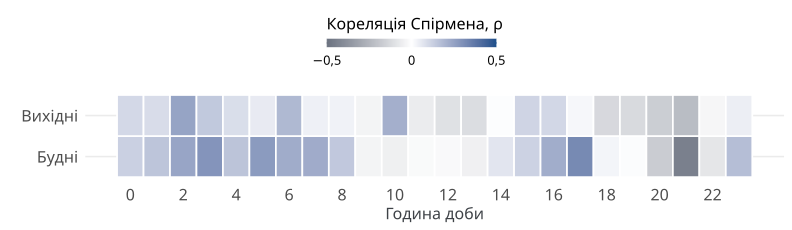

Загальна кореляція Спірмена зовнішньої температури з енергією — **0,22**. У підгрупах вона змінюється від −0,44 до 0,32. Отже, загальний коефіцієнт не описує однаково всі години та типи дня. Розміри груп збережено в таблиці; ці порівняння не є статистичними тестами.

In [14]:
conditional <- data |> group_by(hour, day_type) |> summarise(n = n(),
  rho = cor(T_out, Appliances, method = "spearman"), .groups = "drop")
save_table(conditional, "temperature_by_hour")
p_conditional <- ggplot(conditional, aes(hour, day_type, fill = rho)) +
  geom_tile(colour = paper, linewidth = .8) +
  scale_fill_gradient2(low = "#6B7280", mid = paper, high = blue, limits = c(-.5, .5),
    breaks = c(-.5, 0, .5), labels = c("−0,5", "0", "0,5")) +
  guides(fill = guide_colourbar(barwidth = grid::unit(6, "cm"),
    barheight = grid::unit(.3, "cm"), title.position = "top")) +
  scale_x_continuous(breaks = seq(0, 23, 2)) +
  labs(title = "Зв’язок із температурою залежить від часу", x = "Година доби", y = NULL, fill = "Кореляція Спірмена, ρ")
save_plot(p_conditional, "conditional_temperature", height = 3.2)
overall_temp <- target_cor |> filter(variable == "T_out")
note(paste0("Загальна кореляція Спірмена зовнішньої температури з енергією — **", fmt(overall_temp$spearman, 2),
  "**. У підгрупах вона змінюється від ", fmt(min(conditional$rho), 2), " до ", fmt(max(conditional$rho), 2),
  ". Отже, загальний коефіцієнт не описує однаково всі години та типи дня. Розміри груп збережено в таблиці; ці порівняння не є статистичними тестами."))

### 8.3. Часова залежність
Сусідні десятихвилинні інтервали належать одному будинку й не є незалежними повтореннями. Тому кількість рядків не дорівнює кількості незалежних експериментів; у цій роботі не обчислюємо p-значення та довірчі інтервали за припущенням незалежності всіх рядків.

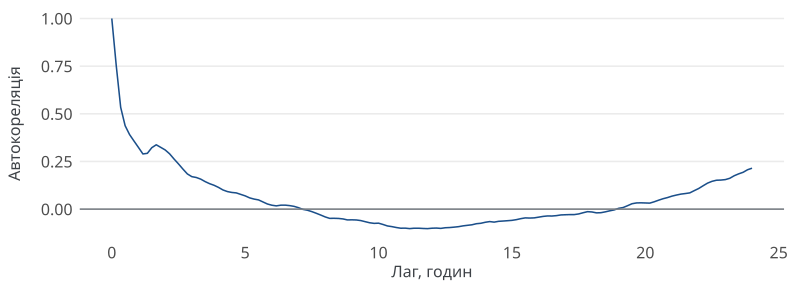

Автокореляція з лагом 10 хвилин — **0,75**. Це суттєва залежність сусідніх значень. У майбутньому моделюванні потрібен часовий поділ, а не випадкове перемішування інтервалів.

In [15]:
acf_values <- acf(data$Appliances, plot = FALSE, lag.max = 144)
autocorrelation <- tibble(lag_intervals = 0:144, lag_hours = (0:144) / 6,
                         acf = as.numeric(acf_values$acf))
save_table(autocorrelation, "autocorrelation")
p_acf <- ggplot(autocorrelation, aes(lag_hours, acf)) + geom_line(colour = blue) +
  geom_hline(yintercept = 0, colour = "#7A7F86") +
  labs(title = "Сусідні вимірювання залежні", x = "Лаг, годин", y = "Автокореляція")
save_plot(p_acf, "autocorrelation", height = 4)
note(paste0("Автокореляція з лагом 10 хвилин — **", fmt(autocorrelation$acf[2], 2),
  "**. Це суттєва залежність сусідніх значень. У майбутньому моделюванні потрібен часовий поділ, а не випадкове перемішування інтервалів."))

## 9. Підсумкові висновки
Відповіді нижче розраховуються з таблиць цієї роботи. Вони описують спостережувані зв’язки, а не причинний вплив факторів.

In [16]:
answers <- tibble(
 question = c("Розподіл і піки", "Добовий профіль", "Будні та вихідні", "Зв’язки з факторами", "Часові підгрупи"),
 answer = c(
  paste0("Медіана ", fmt(target$median, 0), " Wh, середнє ", fmt(target$mean), " Wh. Правий хвіст; ", fmt(mean(data$iqr_flag)*100), "% значень вище межі IQR."),
  paste0("Максимум погодинного середнього о ", peak$hour, ":00: ", fmt(peak$mean), " Wh; мінімум о ", low$hour, ":00: ", fmt(low$mean), " Wh."),
  paste0("У будні ", fmt(week_mean), " Wh, у вихідні ", fmt(end_mean), " Wh за інтервал. Загальна різниця невелика; профілі відрізняються."),
  paste0("Для освітлення rho = ", fmt(target_cor$spearman[target_cor$variable == "lights"], 2), "; для зовнішньої температури rho = ", fmt(overall_temp$spearman, 2), ". Зв’язки обмежені."),
  paste0("Для зовнішньої температури rho у групах година × тип дня: від ", fmt(min(conditional$rho), 2), " до ", fmt(max(conditional$rho), 2), ".")))
save_table(answers, "research_answers")
for (i in seq_len(nrow(answers))) note(paste0("**", i, ". ", answers$question[i], ".** ", answers$answer[i]))

**1. Розподіл і піки.** Медіана 60 Wh, середнє 97,7 Wh. Правий хвіст; 10,8% значень вище межі IQR.

**2. Добовий профіль.** Максимум погодинного середнього о 18:00: 190,4 Wh; мінімум о 3:00: 48,2 Wh.

**3. Будні та вихідні.** У будні 96,6 Wh, у вихідні 100,6 Wh за інтервал. Загальна різниця невелика; профілі відрізняються.

**4. Зв’язки з факторами.** Для освітлення rho = 0,30; для зовнішньої температури rho = 0,22. Зв’язки обмежені.

**5. Часові підгрупи.** Для зовнішньої температури rho у групах година × тип дня: від −0,44 до 0,32.

### Обмеження та подальші дослідження

- Вибірка охоплює один будинок і частину року. Результати не можна автоматично переносити на інші будівлі, домогосподарства або літній і осінній сезони.
- Інформації про присутність мешканців і ввімкнення конкретних приладів немає. Час доби та освітлення можуть лише частково відображати активність.
- Погода з метеостанції частково інтерпольована; кімнатні датчики та зовнішня станція мають різні умови вимірювання.
- Ціль округлена, часовий пояс не задокументований, сусідні інтервали залежні. Піки не мають незалежних міток несправності.
- Подальший аналіз може перевірити стабільність добових профілів на довшому періоді та порівняти кілька будинків. Для майбутньої регресії слід оцінювати якість на пізніших датах і враховувати взаємозалежність температурних факторів.

## 10. Збереження результатів
Оброблений набір зберігає всі вихідні рядки та змінні, календарні ознаки й прапорець IQR. Час експортується текстом без додавання недокументованого часового поясу.

In [17]:
processed <- data |> mutate(timestamp = format(timestamp, "%Y-%m-%d %H:%M:%S", tz = "UTC"))
write_csv(processed, path("data/processed/energy_processed.csv"))
transformations <- tibble(step = c("Імпорт", "Розбір часу", "Календар", "IQR", "Випадкові стовпці"),
  decision = c("CSV; маркери пропусків; перевірка типів", "Без зміни надрукованого часу; пояс невідомий",
    "Додано дату, годину, день тижня, тип дня", "Додано прапорець; рядки не вилучались", "rv1/rv2 збережені, не аналізуються"),
  rows_removed = 0L)
write_csv(transformations, path("outputs/metadata/transformations.csv"))
capture.output(sessionInfo(), file = path("outputs/metadata/sessionInfo.txt"))
stopifnot(nrow(processed) == nrow(raw), sum(is.na(processed)) == 0,
          !anyDuplicated(processed$timestamp), sum(daily$complete) == 136)
cat("Збережено підготовлений датасет, статистичні таблиці, графіки та відомості про середовище.\n")

Збережено підготовлений датасет, статистичні таблиці, графіки та відомості про середовище.
